# ILMT streak detection — paper-method reproduction pilot (single frame)

**Purpose:** test the published Nir, Zackay & Ofek (2018) approach on one selected ILMT FITS image using the authors' reference implementation, [`pyradon`](https://github.com/guynir42/pyradon), before developing a multi-frame pipeline.

## Method fidelity

The reference implementation performs a Fast Radon Transform (FRT) search with:
- background/bias subtraction and PSF filtering;
- a Radon transform of the image variance for line-dependent noise normalization;
- geometric correction for diagonal lines;
- iterative detection and subtraction of multiple candidates;
- threshold scanning to suppress point-source peaks and search for fainter trails;
- both image orientations, so the full range of trail angles is searched.

This is intentionally **not** another custom `skimage.radon` peak-ranking method. The original paper's method is a PSF-matched, variance-normalized FRT search, not simply “find the largest raw Radon sum.”

**Implementation caveat:** the current upstream `src/finder.py` declares a `use_conv` parameter, but its `preprocess()` method unconditionally convolves the image with the PSF. Therefore this pilot does not claim to reproduce the paper’s recommended *paired filtered/unfiltered* artifact comparison. We first establish the reference Finder result; then, if needed, we will add a separately labelled unfiltered FRT diagnostic rather than pretending that `use_conv=False` disables convolution.

## Important ILMT-specific limitation

The FITS headers audited so far do not provide `GAIN` or `RDNOISE`. Therefore this pilot estimates a spatial noise RMS from the image background and uses its square as a variance proxy. This is an empirical estimate, not a calibrated detector-noise model. The estimated PSF must also be inspected. Results should be described as a **faithful implementation of the published algorithm with estimated ILMT preprocessing inputs**, not an exact reproduction of the paper's original instrument conditions.

Paper: Nir, G., Zackay, B. & Ofek, E. O. (2018), *Optimal and Efficient Streak Detection in Astronomical Images*, The Astronomical Journal, 156, 229. https://arxiv.org/abs/1806.04204  
Reference implementation: https://github.com/guynir42/pyradon  

## 0. Configure paths and frame selection

Set `DATA_DIR` to the directory containing the contest FITS files. By default, one frame is selected reproducibly at random (seed 42), not by using `fits_files[0]`. To rerun a particular frame, set `FRAME_FILENAME` to its basename.

In [1]:
from pathlib import Path
import random
import subprocess
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.visualization import ImageNormalize, AsinhStretch, LogStretch, ZScaleInterval, PercentileInterval
import sep

DATA_DIR = Path("ILMT_Contest_Materials/test_files")  # EDIT if your folder differs
FRAME_FILENAME = None  # e.g. "20221026-0057.fits"; None means select a random frame
RANDOM_SEED = 42       # reproducible random selection; set None for a new random choice

fits_files = sorted(DATA_DIR.glob("*.fits"))
if not fits_files:
    raise FileNotFoundError(
        f"No .fits files found in {DATA_DIR.resolve()}. "
        "Update DATA_DIR to your ILMT test_files directory."
    )

if FRAME_FILENAME is None:
    rng = np.random.default_rng(RANDOM_SEED)
    selected_path = Path(rng.choice(fits_files))
else:
    matches = [p for p in fits_files if p.name == FRAME_FILENAME]
    if not matches:
        raise FileNotFoundError(f"{FRAME_FILENAME!r} was not found in {DATA_DIR.resolve()}")
    selected_path = matches[0]

print(f"Found {len(fits_files)} FITS files")
print(f"Selected frame: {selected_path.name}")
print(f"Full path: {selected_path.resolve()}")

Found 85 FITS files
Selected frame: 20230513-0034.fits
Full path: /home/deepmalya/pip_malya/ILMT_Streak_Detection/ILMT_Contest_Materials/test_files/20230513-0034.fits


## 1. Read and audit the selected FITS frame

The image is converted to native-endian float32 for SEP compatibility. This changes storage representation, not the numerical values in any meaningful scientific sense. We do not apply display stretching to the data used by the detector.

In [2]:
with fits.open(selected_path, memmap=False) as hdul:
    header = hdul[0].header.copy()
    raw = np.asarray(hdul[0].data, dtype=np.float32)

if raw.ndim != 2:
    raise ValueError(f"Expected a 2-D primary-HDU image; got shape {raw.shape}")

valid = np.isfinite(raw)
print("Shape:", raw.shape)
print("Dtype:", raw.dtype)
print("Finite fraction:", float(valid.mean()))
print("Median:", float(np.nanmedian(raw)))
print("Robust global sigma (MAD):",
      float(1.4826 * np.nanmedian(np.abs(raw[valid] - np.nanmedian(raw[valid])))))
print("DATE-OBS:", header.get("DATE-OBS"))
print("EXPTIME:", header.get("EXPTIME"))
print("GAIN:", header.get("GAIN"))
print("RDNOISE:", header.get("RDNOISE"))

Shape: (4096, 4096)
Dtype: float32
Finite fraction: 1.0
Median: 3170.156982421875
Robust global sigma (MAD): 149.56124877929688
DATE-OBS: 2023-05-13
EXPTIME: 102.34550550528
GAIN: None
RDNOISE: None


## 2. DS9-style display stretches (visual QA only)

These panels are different mappings of the **same raw pixel values**. They help a human inspect faint structures, but do not themselves improve the numerical signal or establish that a line is a satellite trail.

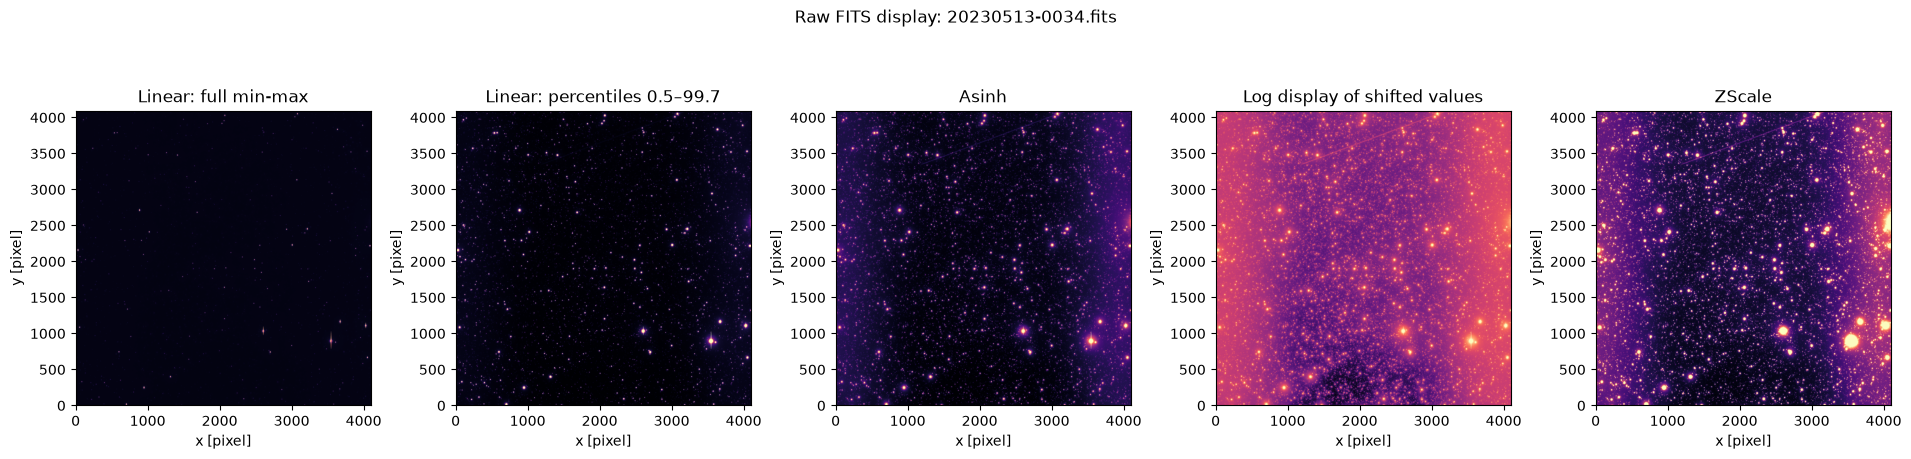

In [3]:
def show_stretches(data, valid_mask=None, title=None, cmap="magma"):
    arr = np.asarray(data, dtype=float)
    good = np.isfinite(arr)
    if valid_mask is not None:
        good &= np.asarray(valid_mask, dtype=bool)
    vals = arr[good]
    if vals.size == 0:
        raise ValueError("No finite pixels to display")

    # Display-only limits, chosen separately for each panel.
    vmin_full, vmax_full = np.nanmin(vals), np.nanmax(vals)
    vmin_pct, vmax_pct = np.nanpercentile(vals, [0.5, 99.7])
    zscale = ZScaleInterval()
    vmin_z, vmax_z = zscale.get_limits(vals)

    views = [
        ("Linear: full min-max", vmin_full, vmax_full, None),
        ("Linear: percentiles 0.5–99.7", vmin_pct, vmax_pct, None),
        ("Asinh", vmin_pct, vmax_pct, AsinhStretch()),
        ("Log display of shifted values", vmin_pct, vmax_pct, LogStretch()),
        ("ZScale", vmin_z, vmax_z, None),
    ]

    fig, axes = plt.subplots(1, len(views), figsize=(19, 4.8), constrained_layout=True)
    for ax, (name, lo, hi, stretch) in zip(axes, views):
        shown = np.array(arr, copy=True)
        shown[~good] = np.nan
        if stretch is None:
            ax.imshow(shown, origin="lower", cmap=cmap, vmin=lo, vmax=hi)
        else:
            # Astropy normalization maps the raw data to the display range.
            norm = ImageNormalize(vmin=lo, vmax=hi, stretch=stretch, clip=True)
            if name.startswith("Log"):
                # LogStretch needs nonnegative values; shift only the display array.
                shown = shown - lo
                shown[~good] = np.nan
                norm = ImageNormalize(vmin=0, vmax=max(hi-lo, np.finfo(float).eps),
                                      stretch=LogStretch(), clip=True)
            ax.imshow(shown, origin="lower", cmap=cmap, norm=norm)
        ax.set_title(name)
        ax.set_xlabel("x [pixel]")
        ax.set_ylabel("y [pixel]")
    if title:
        fig.suptitle(title)
    plt.show()

show_stretches(raw, valid, title=f"Raw FITS display: {selected_path.name}")

## 3. Estimate background and local RMS for the FRT input

The paper requires a background-subtracted image and an image variance estimate. The reference code itself removes residual mean bias and PSF-filters its input, but it does not replace a robust spatial background model. Here SEP supplies a practical spatial background and RMS estimate.

`variance_map = rms_map**2` is the variance proxy passed to the official Finder. Because the detector gain/read noise are unavailable, inspect the background/residual panels and treat the resulting S/N as dependent on this estimated noise model.

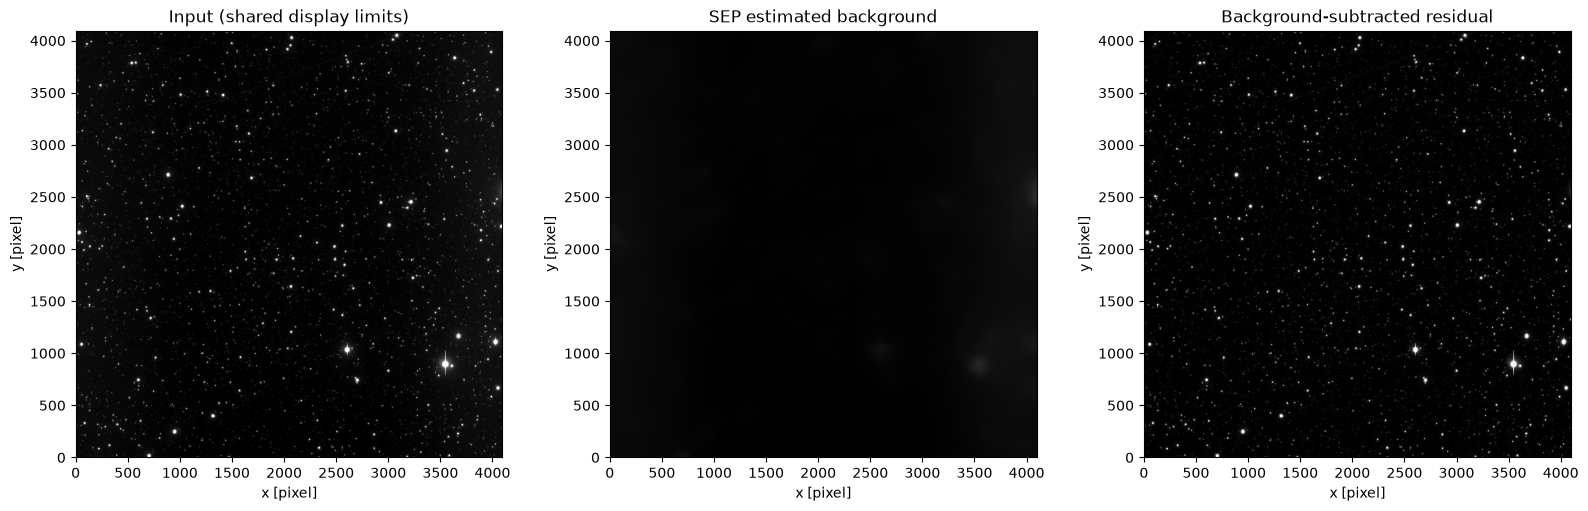

Median estimated background RMS: 29.688106536865234
Median estimated variance: 881.3836697442603


In [4]:
# Keep the same 64-pixel mesh scale used in the earlier prototype for a controlled comparison.
sep_input = np.ascontiguousarray(raw, dtype=np.float32)
sep_mask = ~valid
bkg = sep.Background(sep_input, mask=sep_mask, bw=64, bh=64)
background = np.asarray(bkg.back(), dtype=np.float32)
rms_map = np.asarray(bkg.rms(), dtype=np.float32)
rms_map = np.maximum(rms_map, np.finfo(np.float32).eps)

residual = sep_input - background
residual[~valid] = np.nan
variance_map = rms_map.astype(np.float64)**2
variance_map[~valid] = np.nan

fig, ax = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
lo, hi = np.nanpercentile(raw[valid], [0.5, 99.7])
ax[0].imshow(raw, origin="lower", cmap="gray", vmin=lo, vmax=hi)
ax[0].set_title("Input (shared display limits)")
ax[1].imshow(background, origin="lower", cmap="gray", vmin=lo, vmax=hi)
ax[1].set_title("SEP estimated background")
rlo, rhi = np.nanpercentile(residual[valid], [1, 99.7])
ax[2].imshow(residual, origin="lower", cmap="gray", vmin=rlo, vmax=rhi)
ax[2].set_title("Background-subtracted residual")
for a in ax:
    a.set_xlabel("x [pixel]")
    a.set_ylabel("y [pixel]")
plt.show()

print("Median estimated background RMS:", float(np.nanmedian(rms_map)))
print("Median estimated variance:", float(np.nanmedian(variance_map)))

In [1]:
import numpy as np

image_for_finder = np.ascontiguousarray(
    residual,
    dtype=np.float32,
)

variance_for_finder = np.ascontiguousarray(
    variance_map,
    dtype=np.float32,
)

assert image_for_finder.ndim == 2
assert image_for_finder.shape == variance_for_finder.shape

if not np.all(np.isfinite(variance_for_finder)):
    raise ValueError(
        "Variance map contains NaN or infinite values. "
        "Resolve invalid pixels before running the detector."
    )

if np.any(variance_for_finder <= 0):
    raise ValueError(
        "Variance map must be positive at every valid pixel."
    )

print("Image shape:", image_for_finder.shape)
print("Image dtype:", image_for_finder.dtype)
print("Variance dtype:", variance_for_finder.dtype)
print(
    "Image memory:",
    f"{image_for_finder.nbytes / 1024**2:.1f} MiB",
)
print(
    "Variance memory:",
    f"{variance_for_finder.nbytes / 1024**2:.1f} MiB",
)

NameError: name 'residual' is not defined

## 4. Estimate and inspect the stellar PSF width

Nir et al. describe estimating the PSF from point sources, with a two-dimensional Gaussian as an acceptable approximation when a full empirical PSF is unavailable. The following is a **data-derived preliminary estimate** from SEP's source-shape moments, not a PSF measurement guaranteed to be accurate.

We use unflagged, positive-axis sources with axis ratio ≥ 0.8 as a first-pass round-source sample. This selection is a diagnostic heuristic, not a threshold prescribed by Nir et al. Inspect the histogram and image before accepting the estimate. Saturated/blended stars can bias the result.

Total SEP sources: 10441
Round, unflagged PSF candidates: 4504
Median preliminary Gaussian sigma (pixels): 2.201145457537411
Equivalent FWHM (pixels): 5.183697552500603


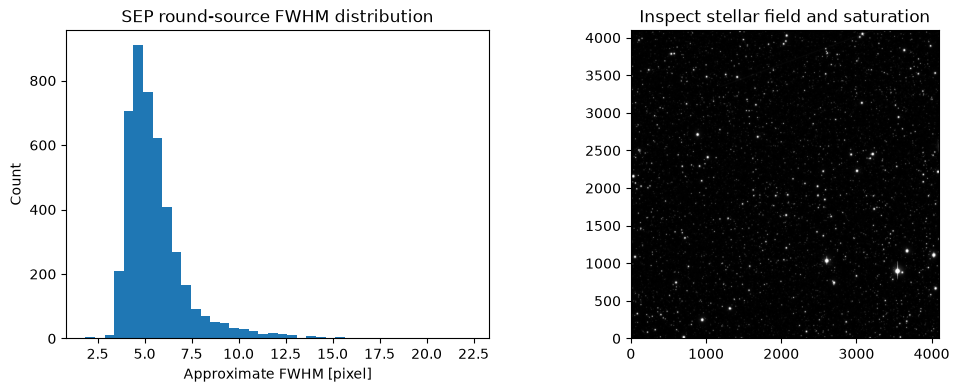

PSF sigma passed to pyradon (provisional): 2.201145457537411


In [5]:
# Detect sources for a preliminary PSF-width diagnostic.
# SEP uses the supplied RMS map for threshold/error handling.
catalog = sep.extract(
    np.ascontiguousarray(np.nan_to_num(residual, nan=0.0), dtype=np.float32),
    thresh=5.0,
    err=np.ascontiguousarray(rms_map, dtype=np.float32),
    mask=np.ascontiguousarray(~valid),
)

if len(catalog) == 0:
    raise RuntimeError("SEP found no sources for a preliminary PSF estimate.")

a = np.asarray(catalog["a"], dtype=float)
b = np.asarray(catalog["b"], dtype=float)
flags = np.asarray(catalog["flag"])
peak = np.asarray(catalog["peak"], dtype=float)

axis_ratio = np.divide(b, a, out=np.zeros_like(b), where=a > 0)
sigma_shape = np.sqrt(np.maximum(a, 0) * np.maximum(b, 0))

# Explicit first-pass selection; inspect the printed count and histogram.
psf_ok = (
    (flags == 0)
    & np.isfinite(sigma_shape)
    & (sigma_shape > 0)
    & (axis_ratio >= 0.8)
)
psf_sigma_candidates = sigma_shape[psf_ok]

if psf_sigma_candidates.size < 10:
    raise RuntimeError(
        f"Only {psf_sigma_candidates.size} round, unflagged sources remain. "
        "Do not trust an automatic PSF estimate; inspect stars manually and set PSF_SIGMA_PIX."
    )

PSF_SIGMA_ESTIMATE = float(np.nanmedian(psf_sigma_candidates))
print("Total SEP sources:", len(catalog))
print("Round, unflagged PSF candidates:", int(psf_sigma_candidates.size))
print("Median preliminary Gaussian sigma (pixels):", PSF_SIGMA_ESTIMATE)
print("Equivalent FWHM (pixels):", 2.355 * PSF_SIGMA_ESTIMATE)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(2.355 * psf_sigma_candidates, bins=40)
ax[0].set_xlabel("Approximate FWHM [pixel]")
ax[0].set_ylabel("Count")
ax[0].set_title("SEP round-source FWHM distribution")
ax[1].imshow(residual, origin="lower", cmap="gray",
             vmin=np.nanpercentile(residual[valid], 1),
             vmax=np.nanpercentile(residual[valid], 99.7))
ax[1].set_title("Inspect stellar field and saturation")
plt.show()

# Use the data-derived estimate as a provisional value. Override manually if
# the histogram/stars indicate contamination or strong spatial PSF variation.
PSF_SIGMA_PIX = PSF_SIGMA_ESTIMATE
print("PSF sigma passed to pyradon (provisional):", PSF_SIGMA_PIX)

In [ ]:
import time
import numpy as np
from pyradon_reference.src.finder import Finder

# Full 4096 x 4096 frame; no arbitrary crop.
full_residual = np.ascontiguousarray(
    np.nan_to_num(residual, nan=0.0),
    dtype=np.float64,
)

full_variance = np.ascontiguousarray(
    variance_map,
    dtype=np.float64,
)

assert full_residual.shape == raw.shape
assert full_variance.shape == raw.shape
assert np.isfinite(full_residual).all()
assert np.isfinite(full_variance).all()
assert np.all(full_variance > 0)

finder = Finder(
    threshold=5.0,
    use_short=True,
    min_length=32,
    num_iterations=5,
    use_exclude=False,
    use_show=False,
    verbosity=2,

    # Process the complete image in sections.
    use_sections=True,
    size_sections=1024,
    pad_sections=False,
)

# Assign the variance map before input().
# Finder.input() calls clear(), which does not clear this field.
finder.data.variance = full_variance

start = time.perf_counter()

finder.input(
    full_residual,
    psf=float(PSF_SIGMA_PIX),
    filename=selected_path.name,
)

elapsed = time.perf_counter() - start

print("Frame:", selected_path.name)
print("Original frame shape:", raw.shape)
print("Elapsed seconds:", round(elapsed, 1))
print("FRT calls:", finder.data._num_frt_calls)
print("Candidates:", len(finder.streaks))
print("Sections:", 16)

mx= 17215.65 | dynamic_range= 1.17e+01 | thresholds: [2.048e+04 1.024e+04 5.120e+03 2.560e+03 1.280e+03 6.400e+02 3.200e+02
 1.600e+02 8.000e+01 4.000e+01 2.000e+01 1.000e+01 5.000e+00]
Running FRT 1 times, transpose= False, thresh= 20480.00, found streak: False
Running FRT 2 times, transpose= True, thresh= 20480.00, found streak: False
Running FRT 3 times, transpose= False, thresh= 10240.00, found streak: False
Running FRT 4 times, transpose= True, thresh= 10240.00, found streak: False
Running FRT 5 times, transpose= False, thresh= 5120.00, found streak: False
Running FRT 6 times, transpose= True, thresh= 5120.00, found streak: False
Running FRT 7 times, transpose= False, thresh= 2560.00, found streak: False
Running FRT 8 times, transpose= True, thresh= 2560.00, found streak: False
Running FRT 9 times, transpose= False, thresh= 1280.00, found streak: False
Running FRT 10 times, transpose= True, thresh= 1280.00, found streak: False
Running FRT 11 times, transpose= False, thresh= 640.00

## 5. Load the authors' reference implementation

The repository is cloned only if it is not already present. The commit hash is printed for reproducibility. This uses the authors' `Finder`, rather than reimplementing its FRT, variance normalization, threshold scanning, or iterative multi-streak search in this notebook.

In [ ]:
PYRADON_DIR = Path("pyradon_reference")

if not PYRADON_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/guynir42/pyradon.git", str(PYRADON_DIR)],
        check=True
    )

git_hash = subprocess.run(
    ["git", "-C", str(PYRADON_DIR), "rev-parse", "HEAD"],
    check=True, capture_output=True, text=True
).stdout.strip()

sys.path.insert(0, str(PYRADON_DIR.resolve()))
from pyradon_reference.src.finder import Finder

print("pyradon repository:", PYRADON_DIR.resolve())
print("pyradon commit:", git_hash)

## 6. Run the official FRT/Finder method on this one frame

The reference implementation expects the background-subtracted image, an estimate of the PSF, and a variance scalar/map. We set the variance map directly on `Finder.data` before calling `input()` because the current repository's `input()` implementation uses a truth test (`if variance`) that is ambiguous for a NumPy array.

For this diagnostic, `use_exclude=False` is deliberate: we do **not** suppress horizontal/vertical candidates before checking the suspected row/column features. The paper and repository document axis-aligned exclusion as an optional way to suppress known sensor artifacts. After this diagnostic, compare with `use_exclude=True` if you have evidence those detector directions are artifacts.

The `threshold=5.0`, `use_short=True`, and `num_iterations=5` values match the reference implementation's defaults. The input image and variance map are not display-stretched.

In [ ]:
# Keep independent copies because Finder iteratively removes candidates from its working image.
finder = Finder(
    threshold=5.0,
    use_short=True,
    min_length=32,
    num_iterations=5,
    use_exclude=False,  # diagnostic: preserve axis-aligned candidates
    use_show=False,
    verbosity=2,
)

# Set variance map directly to avoid NumPy-array truth-value ambiguity in input().
finder.data.variance = np.ascontiguousarray(variance_map, dtype=np.float64)

start = time.perf_counter()
finder.input(
    np.ascontiguousarray(np.nan_to_num(residual, nan=0.0), dtype=np.float64),
    psf=float(PSF_SIGMA_PIX),
    filename=selected_path.name,
)
elapsed = time.perf_counter() - start

print(f"Elapsed seconds: {elapsed:.1f}")
print(f"Candidates retained by Finder: {len(finder.streaks)}")
print(f"FRT calls: {finder.data._num_frt_calls}")

## 7. Inspect all detected candidates against the raw frame

The reference implementation returns candidate `Streak` objects, including endpoints, length, orientation, and its normalized score. These are detections, not automatically verified satellites: the paper explicitly discusses linear artifacts and false positives. Inspect every candidate against the raw frame and the display stretches.

The overlay below uses the reference implementation's endpoints; it does not reconstruct a line from our custom Radon coordinate equations.

Candidates detected: 56
FRT calls: 71


,candidate_id,snr_frt,length_model_px,length_endpoints_px,angle_deg,intensity_I,snr_per_fwhm,x1_crop,y1_crop,x2_crop,y2_crop,threshold,transposed
0,1,250.460537,526.334494,526.334494,166.597417,876.650066,24.701325,512.0,600.0,1024.0,478.0,5.0,True
1,2,246.848990,1024.001953,1024.001953,179.888094,619.439423,17.453913,0.0,368.0,1024.0,366.0,5.0,True
2,3,241.841147,87.045965,87.045965,42.672185,2081.487230,58.649961,64.0,845.0,128.0,904.0,5.0,True
3,4,236.269959,1024.000000,1024.000000,0.000000,592.893115,16.705920,0.0,0.0,1024.0,0.0,5.0,True
4,5,231.441934,69.079664,69.079664,157.890552,2236.067035,63.005549,896.0,492.0,960.0,466.0,5.0,True
5,6,224.091944,513.638978,513.638978,85.421631,793.990190,22.372222,526.0,0.0,567.0,512.0,5.0,False
6,7,220.192897,1024.000000,1024.000000,90.000000,552.549520,15.569160,0.0,0.0,0.0,1024.0,5.0,False
7,8,150.240982,1024.000000,1024.000000,90.000000,377.012989,10.623076,1023.0,0.0,1023.0,1024.0,5.0,False
8,9,132.602288,526.334494,526.334494,166.597417,464.128224,13.077718,512.0,615.0,1024.0,493.0,5.0,True
9,10,132.506523,88.413800,88.413800,43.625165,1131.605657,31.885196,448.0,66.0,512.0,127.0,5.0,True


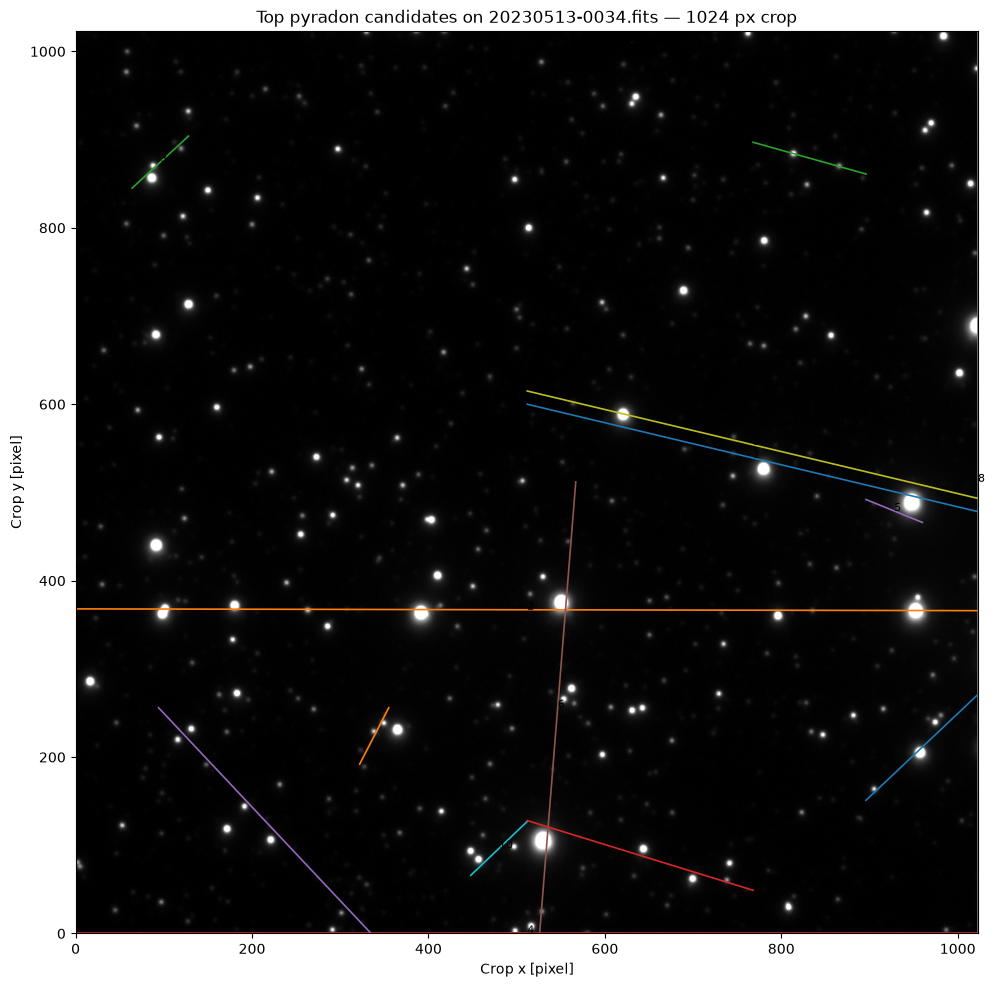

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

finite = raw[np.isfinite(raw)]
vmin, vmax = np.percentile(finite, [1, 99.7])

fig, ax = plt.subplots(figsize=(13, 11))

ax.imshow(
    raw,
    origin="lower",
    cmap="gray",
    vmin=vmin,
    vmax=vmax,
)

for rank, s in enumerate(
    sorted(finder.streaks, key=lambda s: float(s.snr), reverse=True),
    start=1,
):
    x1, y1, x2, y2 = map(
        float, (s.x1f, s.y1f, s.x2f, s.y2f)
    )

    if not np.all(np.isfinite([x1, y1, x2, y2])):
        continue

    ax.plot([x1, x2], [y1, y2], linewidth=1)

ax.set_xlim(0, raw.shape[1] - 1)
ax.set_ylim(0, raw.shape[0] - 1)
ax.set_xlabel("x [pixel]")
ax.set_ylabel("y [pixel]")
ax.set_title(f"Full-frame pyradon detections: {selected_path.name}")

plt.tight_layout()
plt.show()

## 8. Required validation record — do not proceed to 85 frames yet

For this selected frame, record manually:
- which reference candidates align with the horizontal, vertical, and faint diagonal features seen in DS9;
- which candidates align with saturated-star bleed, row/column defects, diffraction features, or other artifacts;
- whether the faint diagonal is recovered at all;
- whether results change materially when the optional axis-aligned exclusion is enabled;
- whether the PSF estimate and local RMS map look plausible.

Do not call a candidate “satellite” solely because it is straight. Nir et al. explicitly note that the algorithm can detect diffraction spikes, pixel bleeding, cosmic rays, and bad-pixel features; classification is a separate task.

### Optional axis-exclusion comparison

Run a second, fresh Finder with the repository's documented exclusion enabled, and compare the candidate list. Do not compare it against a mutated input image from the first run.

In [ ]:
# Optional comparison using the reference repository's default axis-aligned exclusion.
# Leave False until the no-exclusion results above have been inspected.
RUN_AXIS_EXCLUSION_COMPARISON = False

if RUN_AXIS_EXCLUSION_COMPARISON:
    finder_excluded = Finder(
        threshold=5.0,
        use_short=True,
        min_length=32,
        num_iterations=5,
        use_exclude=True,
        use_show=False,
        verbosity=2,
    )
    finder_excluded.data.variance = np.ascontiguousarray(variance_map, dtype=np.float64)
    finder_excluded.input(
        np.ascontiguousarray(np.nan_to_num(residual, nan=0.0), dtype=np.float64),
        psf=float(PSF_SIGMA_PIX),
        filename=selected_path.name,
    )
    print("No-exclusion candidates:", len(finder.streaks))
    print("With-exclusion candidates:", len(finder_excluded.streaks))
    for i, s in enumerate(finder_excluded.streaks):
        print(
            i, f"S/N={s.snr:.2f}", f"L={s.L:.1f}px", f"theta={s.th:.2f}deg",
            f"({s.x1f:.1f},{s.y1f:.1f}) -> ({s.x2f:.1f},{s.y2f:.1f})"
        )

## References and interpretation boundary

1. Nir, G., Zackay, B. & Ofek, E. O. (2018), *Optimal and Efficient Streak Detection in Astronomical Images*, The Astronomical Journal, 156, 229. https://arxiv.org/abs/1806.04204  
2. Authors' reference implementation: https://github.com/guynir42/pyradon  
3. Stoppa, F. et al. (2024), *Automated detection of satellite trails in ground-based observations using U-Net and Hough transform*, Astronomy & Astrophysics, 692, A199. https://doi.org/10.1051/0004-6361/202451663

This notebook is a single-frame reproduction pilot. It does not claim that the method is validated on ILMT. The background and noise map are estimates, and the PSF estimate must be reviewed. Only after inspecting the selected frame and testing other randomly selected frames should we freeze settings and design batch processing.